# Do my late-night YouTube sessions include more videos?
DSA210 · Exploratory analysis

A session belongs to the night group if it starts at or after 22:00 or before 06:00, in Europe/Istanbul time. A gap of at least 30 minutes starts a new session. The 20- and 45-minute definitions are sensitivity checks.

To rerun locally, install Matplotlib, put your personal Takeout ZIP in the notebook directory (or in its `upload` subdirectory), and run all cells. Keep the ZIP outside any public repository.

In [1]:
from collections import Counter
from datetime import datetime, timedelta
from pathlib import Path
from statistics import mean, median
from urllib.parse import urlsplit
from zipfile import ZipFile
from zoneinfo import ZoneInfo
import re

archives = sorted(Path('.').glob('takeout-*.zip')) + sorted(Path('upload').glob('takeout-*.zip'))
if len(archives) != 1:
    raise ValueError('Place exactly one Takeout ZIP beside the notebook or in upload/.')

with ZipFile(archives[0]) as archive:
    member, = (name for name in archive.namelist()
               if Path(name).name in {'izleme geçmişi.html', 'watch-history.html'})
    html = archive.read(member).decode('utf-8')

months = {month: i for i, month in enumerate('Oca Şub Mar Nis May Haz Tem Ağu Eyl Eki Kas Ara'.split(), 1)}
timestamp = re.compile(r'(\d{1,2}) (\w+) (\d{4}) (\d{2}:\d{2}:\d{2}) GMT([+-]\d{2}:\d{2})')
cards = html.split('<div class="outer-cell ')[1:]
counts = Counter()
events = []
istanbul = ZoneInfo('Europe/Istanbul')
for card in cards:
    link = re.search(r'href="([^"]+)"', card)
    url = urlsplit(link[1]) if link else urlsplit('')
    if url.hostname == 'music.youtube.com':
        counts['Music'] += 1
        continue
    if url.hostname != 'www.youtube.com' or not (url.path == '/watch' or url.path.startswith('/shorts/')):
        counts['Other or missing video link'] += 1
        continue
    match = timestamp.search(card)
    if match is None:
        counts['Missing or unsupported timestamp'] += 1
        continue
    day, month, year, clock, offset = match.groups()
    iso = f'{year}-{months[month]:02d}-{int(day):02d}T{clock}{offset}'
    events.append(datetime.fromisoformat(iso).astimezone(istanbul))

events.sort()
assert len(cards) == len(events) + sum(counts.values())
print(f'{len(cards):,} history entries | {len(events):,} retained video records')
print('Exclusions:', dict(counts))
print(f'Video record dates: {events[0].date()} to {events[-1].date()}')

12,990 history entries | 12,841 retained video records
Exclusions: {'Other or missing video link': 16, 'Music': 133}
Video record dates: 2023-11-23 to 2026-11-16


In [2]:
def make_sessions(events, gap_minutes):
    sessions = []
    previous = None
    for event in events:
        if previous is None or event - previous >= timedelta(minutes=gap_minutes):
            period = 'Night' if event.hour >= 22 or event.hour < 6 else 'Day'
            sessions.append({'period': period, 'video_records': 0})
        sessions[-1]['video_records'] += 1
        previous = event
    assert sum(row['video_records'] for row in sessions) == len(events)
    return sessions

groups = {}
for gap in (20, 30, 45):
    sessions = make_sessions(events, gap)
    groups[gap] = {
        period: [row['video_records'] for row in sessions if row['period'] == period]
        for period in ('Night', 'Day')
    }
    for period, sizes in groups[gap].items():
        print(f'{gap:2} min | {period:5} | {len(sizes):,} sessions | '
              f'median {median(sizes):g} | mean {mean(sizes):.2f}')

20 min | Night | 1,236 sessions | median 2 | mean 5.62
20 min | Day   | 1,448 sessions | median 2 | mean 4.07
30 min | Night | 1,086 sessions | median 3 | mean 6.33
30 min | Day   | 1,324 sessions | median 2 | mean 4.50
45 min | Night | 965 sessions | median 3 | mean 7.08
45 min | Day   | 1,236 sessions | median 2 | mean 4.86


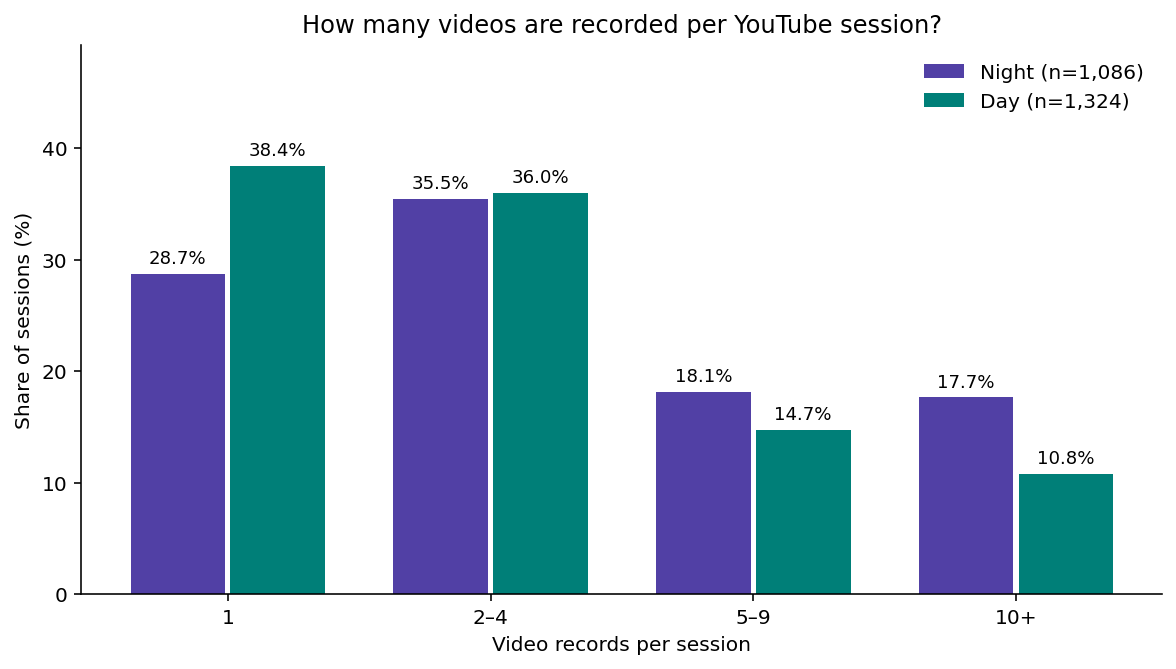

In [3]:
import matplotlib.pyplot as plt

labels = ['1', '2–4', '5–9', '10+']
fig, ax = plt.subplots(figsize=(8, 4.5), layout='constrained')
for period, offset, color in [('Night', -0.19, '#5140A5'), ('Day', 0.19, '#007F78')]:
    sizes = groups[30][period]
    shares = [100 * sum(low <= n <= high for n in sizes) / len(sizes)
              for low, high in [(1, 1), (2, 4), (5, 9), (10, float('inf'))]]
    bars = ax.bar([x + offset for x in range(4)], shares, width=0.36,
                  label=f'{period} (n={len(sizes):,})', color=color)
    ax.bar_label(bars, fmt='%.1f%%', padding=3, fontsize=9)

ax.set_xticks(range(4), labels)
ax.set(xlabel='Video records per session', ylabel='Share of sessions (%)',
       title='How many videos are recorded per YouTube session?')
ax.set_ylim(0, ax.get_ylim()[1] * 1.22)
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

## How much does the upper tail contribute?

Compare the share of sessions with at least 10 records, then recompute the mean difference after excluding those sessions in both groups. This is a descriptive follow-up using an exploratory cutoff.

In [4]:
threshold = 10
all_means = {}
shorter_means = {}
for period, sizes in groups[30].items():
    shorter = [size for size in sizes if size < threshold]
    count_at_least_ten = len(sizes) - len(shorter)
    all_means[period] = mean(sizes)
    shorter_means[period] = mean(shorter)
    print(f'{period}: {count_at_least_ten}/{len(sizes)} sessions with 10+ records '
          f'({count_at_least_ten / len(sizes):.1%})')

print(f'Full mean difference (Night − Day): {all_means["Night"] - all_means["Day"]:.2f}')
print(f'Mean difference below 10 records: {shorter_means["Night"] - shorter_means["Day"]:.2f}')

Night: 192/1086 sessions with 10+ records (17.7%)
Day: 143/1324 sessions with 10+ records (10.8%)
Full mean difference (Night − Day): 1.83
Mean difference below 10 records: 0.36


## Preliminary interpretation

At the 30-minute threshold, nighttime sessions have a higher mean and median than daytime sessions. The mean difference remains positive at all three tested thresholds. The medians match at 20 minutes, so the result for a typical session depends on the session definition.

The analysis counts activity records. It cannot measure viewing duration, completion, autoplay, or why the difference occurs. The evening and overnight time bands and the gap thresholds are analysis choices. The first comparison was exploratory and reflects one account. The mean gap shrinks when sessions with 10 or more records are excluded from both groups, suggesting that the upper tail accounts for much of the observed difference.